# Strefy zarządzania 2D K-Means (`NDVI z-score` + `awc_mm_per_m` w siatce H3 poz. 10)

Pipeline treningowy i walidacyjny (Train 2023–2024 vs Test 2025):
1. **Dane treningowe (2023–2024)** i **testowe (2025)**: do 8 scen Sentinel-2 na sezon wegetacyjny (`03-01` .. `10-31`).
2. **Cechy**: pola `>= 3 ha`, bufor wewnętrzny `10 m`, z-score NDVI per scena/pole + mediana czasowa oraz natywna jednostka gleby `awc_mm_per_m` w komórkach **H3 poziomu 10** (`~250 m`, **bez agregacji do pola**).
3. **Model 2D K-Means** (`[ndvi_z, awc_z]`, `k = 3`: `1 = slaba`, `2 = srednia`, `3 = mocna`) uczony wyłącznie na latach **2023–2024**, zapisywany do `.joblib`.
4. **Moduły testowania modelu** na niewidzianym roku **2025**: metryki jakości klasteryzacji, test generalizacji i stabilności międzyrocznej, wykresy diagnostyczne oraz porównanie przestrzenne pól.

In [25]:
import os
from pathlib import Path
from ndvi_kmeans import (
    ZONE_LABELS_3,
    align_field_prediction_pair,
    compare_train_test_evaluations,
    evaluate_dataset_with_model,
    process_fields_ndvi_kmeans,
    train_kmeans_model,
)
os.environ.setdefault("AWS_NO_SIGN_REQUEST", "YES")
from ndvi_ndmi_downloader import download_clip_sentinel_ndvi_ndmi
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd

BOUNDARY_FILE = Path("data/fields/lowicki_fields_crops.geojson")
SOIL_SOURCE = Path("data/soil/field_soil_h3_cells.parquet")

TRAIN_NDVI_DIR = Path("data/satellite/lowicki_train_2023_2024")
TEST_NDVI_DIR = Path("data/satellite/lowicki_test_2025")
TRAIN_WINDOWS = [("2023-03-01", "2023-10-31"), ("2024-03-01", "2024-10-31")]
TEST_WINDOW = ("2025-03-01", "2025-10-31")
N_SCENES_PER_SEASON = 8

OUT_DIR = Path("data/zones")
TRAIN_OUT_DIR = OUT_DIR / "train_2023_2024"
TEST_OUT_DIR = OUT_DIR / "test_2025"
MODEL_PATH = OUT_DIR / "ndvi_awc_kmeans_model.joblib"
N_CLUSTERS = 3
AWC_WEIGHT = 0.75

## 1. Pobranie i weryfikacja danych satelitarnych (Train 2023–2024 vs Test 2025)

In [26]:
TRAIN_NDVI_DIR.mkdir(parents=True, exist_ok=True)
TEST_NDVI_DIR.mkdir(parents=True, exist_ok=True)

for start_date, end_date in TRAIN_WINDOWS:
    yr = start_date[:4]
    cached = sorted(TRAIN_NDVI_DIR.glob(f"ndvi_ndmi_{yr}-*.tif"))
    if cached:
        print(f"Znaleziono {len(cached)} zcache'owanych scen treningowych dla roku {yr} — pomijam pobieranie.")
    else:
        download_clip_sentinel_ndvi_ndmi(
            boundary_file=BOUNDARY_FILE,
            start_date=start_date,
            end_date=end_date,
            out_dir=TRAIN_NDVI_DIR,
            max_cc=20,
            n_scenes=N_SCENES_PER_SEASON,
            max_missing_ratio=0.3,
        )

test_start, test_end = TEST_WINDOW
test_yr = test_start[:4]
cached_test = sorted(TEST_NDVI_DIR.glob(f"ndvi_ndmi_{test_yr}-*.tif"))
if cached_test:
    print(f"Znaleziono {len(cached_test)} zcache'owanych scen testowych dla roku {test_yr} — pomijam pobieranie.")
else:
    print(f"Pobieranie danych testowych: {test_start} .. {test_end}")
    download_clip_sentinel_ndvi_ndmi(
        boundary_file=BOUNDARY_FILE,
        start_date=test_start,
        end_date=test_end,
        out_dir=TEST_NDVI_DIR,
        max_cc=20,
        n_scenes=N_SCENES_PER_SEASON,
        max_missing_ratio=0.3,
    )

train_tifs = sorted(list(TRAIN_NDVI_DIR.glob("*.tif")) + list(TRAIN_NDVI_DIR.glob("*.tiff")))
test_tifs = sorted(list(TEST_NDVI_DIR.glob("*.tif")) + list(TEST_NDVI_DIR.glob("*.tiff")))
datasets = {"train": train_tifs, "test": test_tifs}

summary_rows = []
for split_name, paths in [("Train (2023-2024)", datasets["train"]), ("Test (2025)", datasets["test"])]:
    by_year = {}
    for p in paths:
        date_str = p.stem.split("_")[2]
        by_year.setdefault(date_str[:4], []).append(date_str)
    for yr, dates in sorted(by_year.items()):
        dates_sorted = sorted(dates)
        summary_rows.append({
            "zbior": split_name,
            "rok": yr,
            "liczba_scen": len(dates_sorted),
            "pierwsza_scena": dates_sorted[0],
            "ostatnia_scena": dates_sorted[-1],
        })

print(f"Zrodlo gleby H3 L10: {SOIL_SOURCE} (istnieje: {SOIL_SOURCE.exists()})")
display(pd.DataFrame(summary_rows))

Znaleziono 8 zcache'owanych scen treningowych dla roku 2023 — pomijam pobieranie.
Znaleziono 8 zcache'owanych scen treningowych dla roku 2024 — pomijam pobieranie.
Znaleziono 8 zcache'owanych scen testowych dla roku 2025 — pomijam pobieranie.
Zrodlo gleby H3 L10: data\soil\field_soil_h3_cells.parquet (istnieje: True)


,zbior,rok,liczba_scen,pierwsza_scena,ostatnia_scena
0,Train (2023-2024),2023,8,2023-04-22,2023-09-29
1,Train (2023-2024),2024,8,2024-04-11,2024-10-18
2,Test (2025),2025,8,2025-03-19,2025-09-25


## 2. Trening modelu 2D K-Means na danych treningowych (2023–2024)

In [27]:
model, meta = train_kmeans_model(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TRAIN_NDVI_DIR,
    model_path=MODEL_PATH,
    n_clusters=N_CLUSTERS,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    soil_source=SOIL_SOURCE,
    awc_weight=AWC_WEIGHT,
    awc_norm="within_field",
    awc_min_std=2.5,
)
meta

Pole 395: pominieto (brak wystarczajacych pikseli NDVI).
Pole 479: pominieto (brak wystarczajacych pikseli NDVI).
Pole 693: pominieto (brak wystarczajacych pikseli NDVI).
Pole 798: pominieto (brak wystarczajacych pikseli NDVI).
Pole 800: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1290: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1382: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1480: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1851: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1937: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1938: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1970: pominieto (brak wystarczajacych pikseli NDVI).
Pole 2122: pominieto (brak wystarczajacych pikseli NDVI).
Pole 2140: pominieto (brak wystarczajacych pikseli NDVI).


{'n_fields': 2347,
 'n_pixels': 1097393,
 'n_scenes': 16,
 'inner_buffer_m': 10.0,
 'min_area_ha': 3.0,
 'random_state': 42,
 'zone_empirical_means': {'1': {'ndvi_z': -0.5924, 'awc_z': -0.4878},
  '2': {'ndvi_z': 0.0321, 'awc_z': 0.0054},
  '3': {'ndvi_z': 0.6506, 'awc_z': 0.6186}},
 'awc_weight': 0.75,
 'awc_unit': 'h3_index_10',
 'awc_norm': 'within_field',
 'awc_min_std': 2.5}

## 3. Wyznaczenie stref zarządzania dla zbioru treningowego (2023–2024) i testowego (2025)

In [20]:
train_zones_gdf = process_fields_ndvi_kmeans(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TRAIN_NDVI_DIR,
    out_dir=TRAIN_OUT_DIR,
    model_path=MODEL_PATH,
    load_model=True,
    soil_source=SOIL_SOURCE,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    min_zone_area_ha=0.15,
    apply_majority_filter=True,
    save_rasters=False,
)

test_zones_gdf = process_fields_ndvi_kmeans(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TEST_NDVI_DIR,
    out_dir=TEST_OUT_DIR,
    model_path=MODEL_PATH,
    load_model=True,
    soil_source=SOIL_SOURCE,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    min_zone_area_ha=0.15,
    apply_majority_filter=True,
    save_rasters=False,
)

for title, gdf_res in [("Train (2023-2024)", train_zones_gdf), ("Test (2025)", test_zones_gdf)]:
    print(f"\n=== Podsumowanie wektorowych stref: {title} ===")
    display(
        gdf_res.groupby(["zone", "zone_label"])
        .agg(
            polygons=("area_ha", "count"),
            total_area_ha=("area_ha", "sum"),
            mean_ndvi_z=("ndvi_z", "mean"),
            mean_awc_mm_per_m=("awc_mm_per_m", "mean"),
        )
        .round(3)
    )

Pole 395: pominieto (brak wystarczajacych pikseli NDVI).
Pole 479: pominieto (brak wystarczajacych pikseli NDVI).
Pole 693: pominieto (brak wystarczajacych pikseli NDVI).
Pole 798: pominieto (brak wystarczajacych pikseli NDVI).
Pole 800: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1290: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1382: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1480: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1851: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1937: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1938: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1970: pominieto (brak wystarczajacych pikseli NDVI).
Pole 2122: pominieto (brak wystarczajacych pikseli NDVI).
Pole 2140: pominieto (brak wystarczajacych pikseli NDVI).
Pole 395: pominieto (brak wystarczajacych pikseli NDVI).
Pole 479: pominieto (brak wystarczajacych pikseli NDVI).
Pole 693: pominieto (brak wystarczajacych pikseli NDVI).
Pole 798: pominieto (b

,,polygons,total_area_ha,mean_ndvi_z,mean_awc_mm_per_m
zone,zone_label,,,,
1,slaba,4643,3356.420,-0.490,94.419
2,srednia,6829,5102.112,0.030,95.497
3,mocna,4014,2508.316,0.554,97.338



=== Podsumowanie wektorowych stref: Test (2025) ===


,,polygons,total_area_ha,mean_ndvi_z,mean_awc_mm_per_m
zone,zone_label,,,,
1,slaba,4873,3237.511,-0.467,94.329
2,srednia,7226,5596.758,0.007,95.399
3,mocna,3684,2132.586,0.497,97.694


## 4. Moduły testowania i walidacji modelu

- **Moduł 1**: Nienadzorowane metryki jakości klasteryzacji (`Silhouette`, `Davies-Bouldin`, `Calinski-Harabasz`, inercja/piksel) oraz kontrola monotoniczności cech agronomicznych w strefach `1 < 2 < 3`.
- **Moduł 2**: Test generalizacji granic decyzyjnych (zamrożony model 2023–2024 vs niezależny refit na 2025) oraz stabilność międzyroczna stref piksel-po-pikselu (`Agreement %`, `Cohen's kappa`, `Weighted kappa`, `ARI`, macierz przejść).
- **Moduł 3**: Wykresy diagnostyczne (macierz przejść, przestrzeń cech `[ndvi_z, awc_z]`, udział powierzchni stref, histogram stabilności pól).
- **Moduł 4**: Przestrzenne porównanie stref Train (`2023–2024`) vs Test (`2025`) oraz mapy zgodności dla wybranego pola.

In [21]:
# MODUŁ 1: Ewaluacja na zbiorze treningowym (2023-2024) i testowym (2025)
train_eval = evaluate_dataset_with_model(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TRAIN_NDVI_DIR,
    model_path=MODEL_PATH,
    soil_source=SOIL_SOURCE,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    awc_norm="within_field",
    awc_min_std=2.5,
    apply_majority_filter=True,
)
test_eval = evaluate_dataset_with_model(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=TEST_NDVI_DIR,
    model_path=MODEL_PATH,
    soil_source=SOIL_SOURCE,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    awc_norm="within_field",
    awc_min_std=2.5,
    apply_majority_filter=True,
)

X, labels = test_eval["X"], test_eval["labels"]
sil = silhouette_score(X, labels, sample_size=20_000, random_state=42)
db = davies_bouldin_score(X, labels)
ch = calinski_harabasz_score(X, labels)
print(f"Test 2025 (2D) -> Silhouette: {sil:.3f} | Davies-Bouldin: {db:.3f} | Calinski-Harabasz: {ch:.1f}")

comparison = compare_train_test_evaluations(train_eval, test_eval, n_clusters=N_CLUSTERS)

print("\n=== Porownanie metryk jakosci: Train (2023-2024) vs Test (2025) ===")
display(comparison["summary_comparison_df"])

for label_set, eval_obj in [("Train (2023-2024)", train_eval), ("Test (2025)", test_eval)]:
    m = eval_obj["metrics"]
    status_ndvi = "PASS" if m["monotonic_ndvi_z"] else "WARN"
    status_awc_z = "PASS" if m["monotonic_awc_z"] else "WARN"
    status_awc_raw = "PASS" if m["monotonic_awc_raw"] else "WARN"
    print(
        f"{label_set}: monotonicznosc ndvi_z={status_ndvi}, awc_z={status_awc_z}, "
        f"awc_mm_per_m={status_awc_raw} | pola z 3 strefami: {m['pct_fields_all_zones']:.1f}%"
    )
    display(eval_obj["zone_summary_df"].round(3))

Pole 395: pominieto (brak wystarczajacych pikseli NDVI).
Pole 479: pominieto (brak wystarczajacych pikseli NDVI).
Pole 693: pominieto (brak wystarczajacych pikseli NDVI).
Pole 798: pominieto (brak wystarczajacych pikseli NDVI).
Pole 800: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1290: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1382: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1480: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1851: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1937: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1938: pominieto (brak wystarczajacych pikseli NDVI).
Pole 1970: pominieto (brak wystarczajacych pikseli NDVI).
Pole 2122: pominieto (brak wystarczajacych pikseli NDVI).
Pole 2140: pominieto (brak wystarczajacych pikseli NDVI).
Pole 395: pominieto (brak wystarczajacych pikseli NDVI).
Pole 479: pominieto (brak wystarczajacych pikseli NDVI).
Pole 693: pominieto (brak wystarczajacych pikseli NDVI).
Pole 798: pominieto (b

,metric,train_2023_2024,test_2025,delta
0,n_scenes,16,8,-8.0
1,n_fields,2347,2347,0.0
2,n_pixels,1097393,1097393,0.0
3,silhouette_2d,0.2186,0.2267,0.0082
4,davies_bouldin_2d,1.5499,1.4774,-0.0725
5,calinski_harabasz_2d,351485.693,353295.7671,1810.0741
6,silhouette_1d,0.5248,0.5266,0.0019
7,davies_bouldin_1d,0.5732,0.5746,0.0013
8,calinski_harabasz_1d,2183902.9757,2009131.2056,-174771.7701
9,inertia_per_pixel,0.5897,0.5565,-0.0331


Train (2023-2024): monotonicznosc ndvi_z=PASS, awc_z=PASS, awc_mm_per_m=PASS | pola z 3 strefami: 98.5%


,zone,zone_label,n_pixels,share_pct,mean_ndvi_z,std_ndvi_z,mean_awc_z,std_awc_z,mean_awc_mm_per_m,std_awc_mm_per_m
0,1,slaba,336763,30.69,-0.581,0.415,-0.490,0.556,93.408,7.471
1,2,srednia,502379,45.78,0.033,0.483,0.007,0.567,94.777,7.810
2,3,mocna,258251,23.53,0.640,0.509,0.625,0.755,96.838,8.875


Test (2025): monotonicznosc ndvi_z=PASS, awc_z=PASS, awc_mm_per_m=PASS | pola z 3 strefami: 98.2%


,zone,zone_label,n_pixels,share_pct,mean_ndvi_z,std_ndvi_z,mean_awc_z,std_awc_z,mean_awc_mm_per_m,std_awc_mm_per_m
0,1,slaba,325434,29.66,-0.532,0.443,-0.543,0.555,93.583,7.518
1,2,srednia,548068,49.94,0.011,0.423,0.027,0.520,94.388,7.686
2,3,mocna,223891,20.40,0.555,0.529,0.723,0.771,97.783,9.009


In [22]:
# MODUŁ 2: Generalizacja granic decyzyjnych i stabilnosc czasowa (2023-2024 vs 2025)
gen = comparison["generalization"]
stab = comparison["stability"]

print("=== Test generalizacji modelu (zamrozony model 2023-2024 vs niezalezny refit na 2025) ===")
print(f"  Zgodnosc przypisan pikseli: {gen['frozen_vs_refit_agreement_pct']:.2f}%")
print(f"  Cohen's kappa (frozen vs refit): {gen['frozen_vs_refit_kappa']:.4f}")
print(f"  Maks. przesuniecie centroidu (L2): {gen['max_centroid_shift_l2']:.4f}")

centroids_df = pd.DataFrame({
    "zone": [1, 2, 3],
    "train_ndvi_z": np.round(train_eval["model"].cluster_centers_[:, 0], 4),
    "train_awc_z": np.round(train_eval["model"].cluster_centers_[:, 1], 4),
    "refit2025_ndvi_z": np.round(comparison["refit_centers"][:, 0], 4),
    "refit2025_awc_z": np.round(comparison["refit_centers"][:, 1], 4),
    "shift_l2": gen["centroid_shifts_l2"],
})
display(centroids_df)

print("\n=== Stabilnosc miedzyroczna stref (Train 2023-2024 vs Test 2025, piksel-po-pikselu) ===")
for k, v in stab.items():
    print(f"  {k}: {v}")

print("\n=== Macierz przejsc stref [%] (wiersze = Train 2023-2024, kolumny = Test 2025) ===")
display(comparison["confusion_norm_df"])

print("\n=== Rozklad stabilnosci w obrebie poszczegolnych pol [%] ===")
display(
    comparison["per_field_stability_df"][
        ["agreement_pct", "adjacent_or_exact_pct", "extreme_flip_pct", "ndvi_z_corr"]
    ]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .round(2)
)

=== Test generalizacji modelu (zamrozony model 2023-2024 vs niezalezny refit na 2025) ===
  Zgodnosc przypisan pikseli: 98.57%
  Cohen's kappa (frozen vs refit): 0.9773
  Maks. przesuniecie centroidu (L2): 0.0283


,zone,train_ndvi_z,train_awc_z,refit2025_ndvi_z,refit2025_awc_z,shift_l2
0,1,-0.6151,-0.4614,-0.6149,-0.4612,0.0003
1,2,0.0206,0.0154,0.0075,0.0056,0.0164
2,3,0.7109,0.5332,0.6883,0.5162,0.0283



=== Stabilnosc miedzyroczna stref (Train 2023-2024 vs Test 2025, piksel-po-pikselu) ===
  n_common_fields: 2347
  n_common_pixels: 1097393
  exact_agreement_pct: 57.2
  adjacent_or_exact_pct: 96.46
  extreme_flip_pct: 3.54
  cohen_kappa: 0.3231
  weighted_kappa_quadratic: 0.481
  adjusted_rand_index: 0.1178
  normalized_mutual_info: 0.1272
  ndvi_z_pearson_r: 0.264

=== Macierz przejsc stref [%] (wiersze = Train 2023-2024, kolumny = Test 2025) ===


,Test: 1 (slaba),Test: 2 (srednia),Test: 3 (mocna)
Train: 1 (slaba),56.37,38.52,5.11
Train: 2 (srednia),22.68,61.67,15.65
Train: 3 (mocna),8.39,42.03,49.59



=== Rozklad stabilnosci w obrebie poszczegolnych pol [%] ===


,agreement_pct,adjacent_or_exact_pct,extreme_flip_pct,ndvi_z_corr
count,2347.00,2347.00,2347.00,2347.00
mean,59.22,96.89,3.11,0.32
std,18.97,5.97,5.97,0.42
min,0.00,26.02,0.00,-0.98
10%,33.01,90.86,0.00,-0.29
25%,47.48,96.34,0.00,0.04
50%,61.47,99.38,0.62,0.39
75%,73.13,100.00,3.66,0.66
90%,82.29,100.00,9.14,0.81
max,100.00,100.00,73.98,1.00


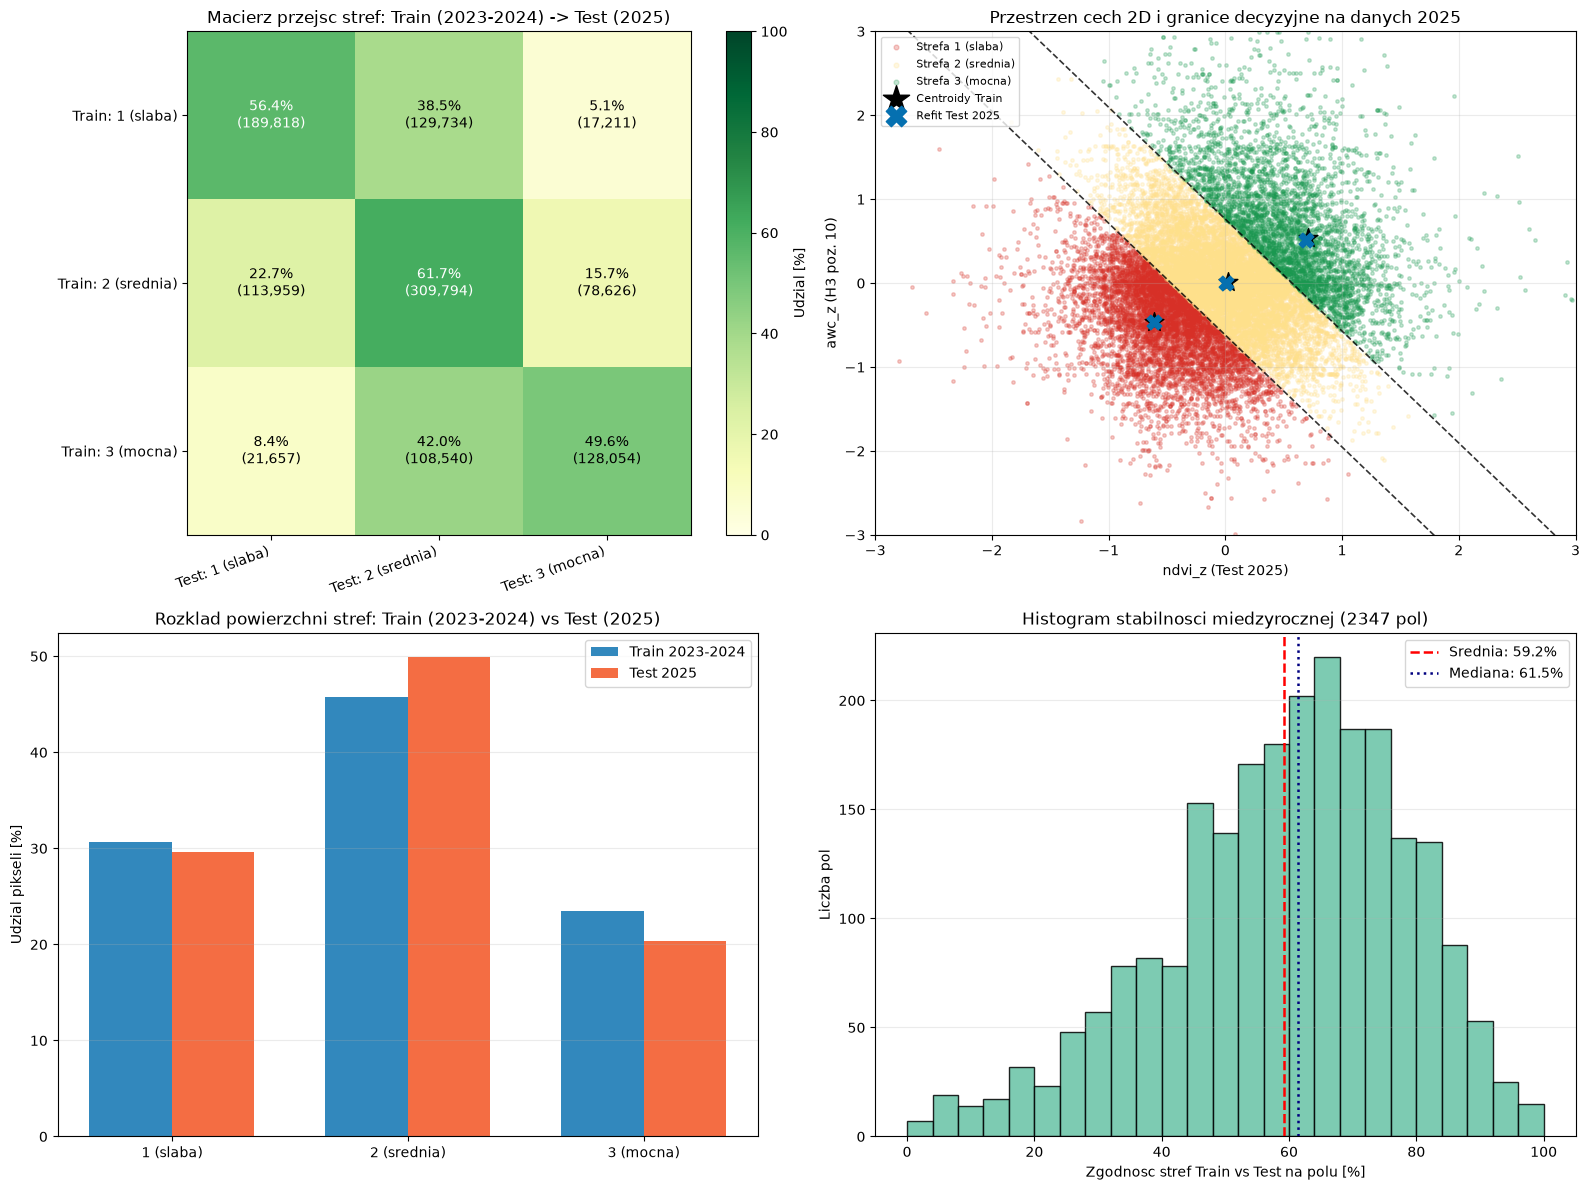

In [23]:
# MODUŁ 3: Wykresy diagnostyczne modelu
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
zone_colors = {1: "#d73027", 2: "#fee08b", 3: "#1a9850"}

# 1. Macierz przejsc stref (Train 2023-2024 -> Test 2025)
cm_pct = comparison["confusion_norm_df"].to_numpy()
cm_cnt = comparison["confusion_counts_df"].to_numpy()
im_cm = axes[0, 0].imshow(cm_pct, cmap="YlGn", vmin=0, vmax=100)
axes[0, 0].set_xticks(range(N_CLUSTERS))
axes[0, 0].set_yticks(range(N_CLUSTERS))
axes[0, 0].set_xticklabels(comparison["confusion_norm_df"].columns, rotation=20, ha="right")
axes[0, 0].set_yticklabels(comparison["confusion_norm_df"].index)
axes[0, 0].set_title("Macierz przejsc stref: Train (2023-2024) -> Test (2025)")
for i in range(N_CLUSTERS):
    for j in range(N_CLUSTERS):
        txt_color = "white" if cm_pct[i, j] > 55 else "black"
        axes[0, 0].text(
            j, i, f"{cm_pct[i, j]:.1f}%\n({cm_cnt[i, j]:,})",
            ha="center", va="center", color=txt_color, fontsize=10,
        )
plt.colorbar(im_cm, ax=axes[0, 0], fraction=0.046, label="Udzial [%]")

# 2. Przestrzen cech 2D [ndvi_z, awc_z] na probce pikseli testowych 2025
sdf = test_eval["sample_df"]
for z in range(1, N_CLUSTERS + 1):
    sub = sdf[sdf["zone_raw"] == z]
    axes[0, 1].scatter(
        sub["ndvi_z"], sub["awc_z"], s=6, alpha=0.25,
        color=zone_colors[z], label=f"Strefa {z} ({ZONE_LABELS_3[z]})",
    )
tr_c = train_eval["model"].cluster_centers_
rf_c = comparison["refit_centers"]
scores = tr_c[:, 0] + AWC_WEIGHT * tr_c[:, 1]
ndvi_line = np.linspace(-3.0, 3.0, 100)
for k in range(N_CLUSTERS - 1):
    thresh = 0.5 * (scores[k] + scores[k + 1])
    awc_line = (thresh - ndvi_line) / AWC_WEIGHT
    axes[0, 1].plot(ndvi_line, awc_line, "k--", linewidth=1.2, alpha=0.8)
axes[0, 1].scatter(tr_c[:, 0], tr_c[:, 1], marker="*", s=200, color="black", zorder=5, label="Centroidy Train")
axes[0, 1].scatter(rf_c[:, 0], rf_c[:, 1], marker="X", s=110, color="#0570b0", zorder=6, label="Refit Test 2025")
axes[0, 1].set_xlim(-3.0, 3.0)
axes[0, 1].set_ylim(-3.0, 3.0)
axes[0, 1].set_xlabel("ndvi_z (Test 2025)")
axes[0, 1].set_ylabel("awc_z (H3 poz. 10)")
axes[0, 1].set_title("Przestrzen cech 2D i granice decyzyjne na danych 2025")
axes[0, 1].legend(loc="upper left", fontsize=8, markerscale=1.4)
axes[0, 1].grid(alpha=0.25)

# 3. Udzial stref (%) w Train vs Test
tr_zs = train_eval["zone_summary_df"].set_index("zone")
te_zs = test_eval["zone_summary_df"].set_index("zone")
x_pos = np.arange(N_CLUSTERS)
width = 0.35
axes[1, 0].bar(x_pos - width / 2, [tr_zs.loc[z, "share_pct"] for z in range(1, N_CLUSTERS + 1)], width, label="Train 2023-2024", color="#3288bd")
axes[1, 0].bar(x_pos + width / 2, [te_zs.loc[z, "share_pct"] for z in range(1, N_CLUSTERS + 1)], width, label="Test 2025", color="#f46d43")
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels([f"{z} ({ZONE_LABELS_3[z]})" for z in range(1, N_CLUSTERS + 1)])
axes[1, 0].set_ylabel("Udzial pikseli [%]")
axes[1, 0].set_title("Rozklad powierzchni stref: Train (2023-2024) vs Test (2025)")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", alpha=0.25)

# 4. Histogram stabilnosci per pole
pf_df = comparison["per_field_stability_df"]
axes[1, 1].hist(pf_df["agreement_pct"], bins=25, color="#66c2a5", edgecolor="black", alpha=0.85)
mean_agr = float(pf_df["agreement_pct"].mean())
med_agr = float(pf_df["agreement_pct"].median())
axes[1, 1].axvline(mean_agr, color="red", linestyle="--", linewidth=1.8, label=f"Srednia: {mean_agr:.1f}%")
axes[1, 1].axvline(med_agr, color="navy", linestyle=":", linewidth=1.8, label=f"Mediana: {med_agr:.1f}%")
axes[1, 1].set_xlabel("Zgodnosc stref Train vs Test na polu [%]")
axes[1, 1].set_ylabel("Liczba pol")
axes[1, 1].set_title(f"Histogram stabilnosci miedzyrocznej ({len(pf_df)} pol)")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

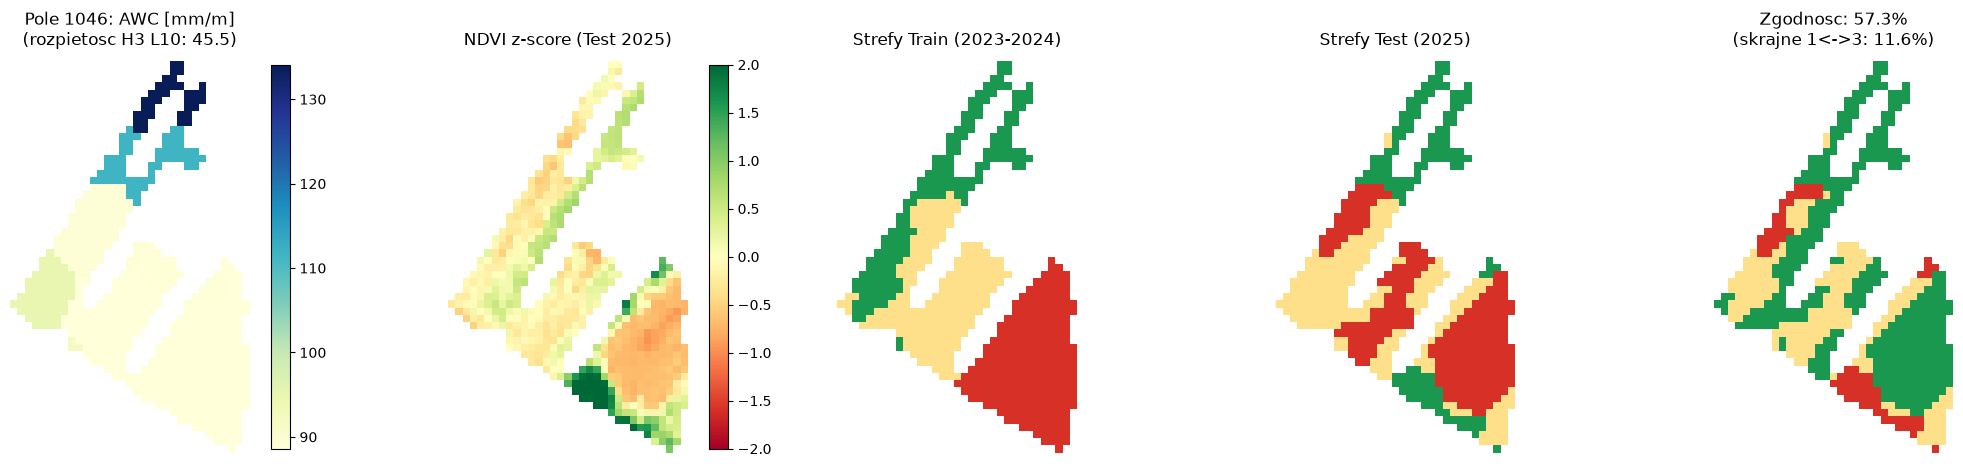

In [24]:
# MODUŁ 4: Porownanie przestrzenne stref Train (2023-2024) vs Test (2025) dla przykladowego pola
pf_candidates = comparison["per_field_stability_df"]
pf_large = pf_candidates[pf_candidates["n_pixels"] >= 200]
candidate_ids = pf_large["field_id"].tolist() if not pf_large.empty else pf_candidates["field_id"].tolist()

best_fid = candidate_ids[0]
best_span = -1.0
for fid in candidate_ids:
    ag = test_eval["field_predictions"][fid].get("awc_grid")
    if ag is None:
        continue
    vals = ag[np.isfinite(ag)]
    if vals.size == 0:
        continue
    span = float(np.max(vals) - np.min(vals))
    if span > best_span:
        best_span = span
        best_fid = fid

tr_z, te_z, tr_ndvi, te_ndvi, awc_grid = align_field_prediction_pair(
    train_eval["field_predictions"][best_fid],
    test_eval["field_predictions"][best_fid],
)
overlap = (tr_z > 0) & (te_z > 0)
diff_code = np.full(tr_z.shape, np.nan, dtype=float)
abs_d = np.abs(tr_z.astype(np.int16) - te_z.astype(np.int16))
diff_code[overlap & (abs_d == 0)] = 1.0  # identyczna strefa
diff_code[overlap & (abs_d == 1)] = 2.0  # przesuniecie o 1 strefe
diff_code[overlap & (abs_d >= 2)] = 3.0  # skrajna zmiana (slaba <-> mocna)

field_row = pf_candidates[pf_candidates["field_id"] == best_fid].iloc[0]
tr_plot = np.where(tr_z > 0, tr_z.astype(float), np.nan)
te_plot = np.where(te_z > 0, te_z.astype(float), np.nan)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
zone_cmap = ListedColormap(["#d73027", "#fee08b", "#1a9850"])
diff_cmap = ListedColormap(["#1a9850", "#fee08b", "#d73027"])

im0 = axes[0].imshow(awc_grid, cmap="YlGnBu")
axes[0].set_title(f"Pole {best_fid}: AWC [mm/m]\n(rozpietosc H3 L10: {best_span:.1f})")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(te_ndvi, cmap="RdYlGn", vmin=-2, vmax=2)
axes[1].set_title("NDVI z-score (Test 2025)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].imshow(tr_plot, cmap=zone_cmap, vmin=1, vmax=3, interpolation="nearest")
axes[2].set_title("Strefy Train (2023-2024)")

axes[3].imshow(te_plot, cmap=zone_cmap, vmin=1, vmax=3, interpolation="nearest")
axes[3].set_title("Strefy Test (2025)")

axes[4].imshow(diff_code, cmap=diff_cmap, vmin=1, vmax=3, interpolation="nearest")
axes[4].set_title(
    f"Zgodnosc: {field_row['agreement_pct']:.1f}%\n"
    f"(skrajne 1<->3: {field_row['extreme_flip_pct']:.1f}%)"
)

for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()